## Use Variance Inflation Factor (VIF) to detect multicollinearity by manually computing R-squared values for each feature without using built-in regression or multicollinearity functions, and provide a detailed interpretation of results.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('heart.csv')             
X = df.drop(columns='target')               
print(X.shape, '| missing values:', int(X.isna().sum().sum()))
X.head()

(303, 13) | missing values: 0


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2


In [2]:
def r_squared(y, A):
    A = np.c_[np.ones(len(A)), A]                       
    beta = np.linalg.solve(A.T @ A, A.T @ y)            
    ss_res = np.sum((y - A @ beta) ** 2)               
    ss_tot = np.sum((y - y.mean()) ** 2)               
    return 1 - ss_res / ss_tot

In [3]:
def vif_table(Xd):
    d = Xd.values.astype(float); rows = []
    for j, col in enumerate(Xd.columns):
        others = np.delete(d, j, axis=1)                  
        r2 = r_squared(d[:, j], others)
        rows.append((col, r2, 1 / (1 - r2)))
    t = pd.DataFrame(rows, columns=['feature', 'R2', 'VIF']).sort_values('VIF', ascending=False).reset_index(drop=True)
    t['level'] = np.where(t['VIF'] >= 10, 'High', np.where(t['VIF'] >= 5, 'Moderate', 'Low'))
    return t

vif = vif_table(X)
vif.round(3)

,feature,R2,VIF,level
0,oldpeak,0.414,1.706,Low
1,slope,0.391,1.643,Low
2,thalach,0.380,1.614,Low
3,age,0.307,1.443,Low
4,exang,0.287,1.402,Low
5,cp,0.221,1.284,Low
6,ca,0.168,1.203,Low
7,trestbps,0.146,1.171,Low
8,sex,0.139,1.162,Low
9,chol,0.131,1.150,Low


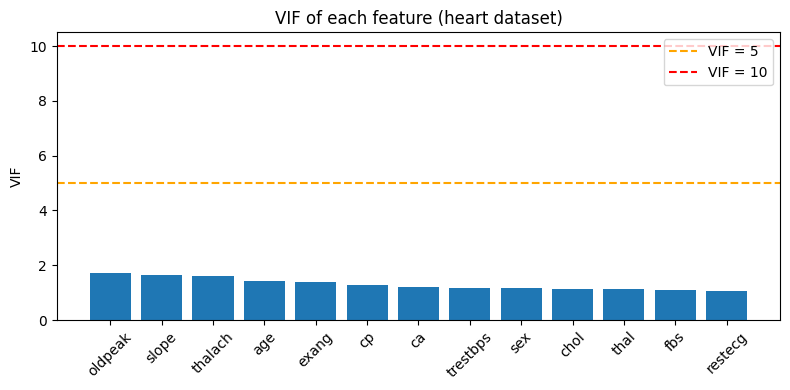

In [4]:
plt.figure(figsize=(8, 4))
plt.bar(vif['feature'], vif['VIF'], color='tab:blue')
plt.axhline(5, color='orange', ls='--', label='VIF = 5'); plt.axhline(10, color='red', ls='--', label='VIF = 10')
plt.xticks(rotation=45); plt.ylabel('VIF'); plt.title('VIF of each feature (heart dataset)')
plt.legend(); plt.tight_layout(); plt.show()

In [5]:
data = X.values.astype(float)
Z = (data - data.mean(0)) / data.std(0)
corr = Z.T @ Z / len(Z)                               
check = np.diag(np.linalg.inv(corr))
print('Max difference between two methods:', np.abs(check - vif.set_index('feature').loc[X.columns, 'VIF'].values).max())

Max difference between two methods: 3.774758283725532e-15


In [6]:
pairs = [(X.columns[i], X.columns[j], corr[i, j]) for i in range(len(corr)) for j in range(i + 1, len(corr))]
top = sorted(pairs, key=lambda p: -abs(p[2]))[:6]
for a, b, r in top:
    print(f'{a:9s} - {b:9s} correlation = {r:6.3f}')

oldpeak   - slope     correlation = -0.578
age       - thalach   correlation = -0.399
cp        - exang     correlation = -0.394
thalach   - slope     correlation =  0.387
thalach   - exang     correlation = -0.379
thalach   - oldpeak   correlation = -0.344


In [7]:
cat_cols = ['cp', 'restecg', 'slope', 'thal']

def encode(pick_reference):
    out = X.copy()
    for c in cat_cols:
        ref = pick_reference(X[c])                          # jo category hatani hai
        dummies = pd.get_dummies(X[c], prefix=c).astype(float).drop(columns=f'{c}_{ref}')
        out = pd.concat([out.drop(columns=c), dummies], axis=1)
    return out

print('Reference = pehli (sabse chhoti label) category:')
print(vif_table(encode(lambda s: s.min())).head(3).round(2)[['feature', 'VIF']].to_string(index=False))
print('\nReference = sabse common category:')
print(vif_table(encode(lambda s: s.value_counts().idxmax())).head(3).round(2)[['feature', 'VIF']].to_string(index=False))

Reference = pehli (sabse chhoti label) category:
feature   VIF
 thal_2 39.01
 thal_3 37.86
 thal_1  9.72

Reference = sabse common category:
feature  VIF
oldpeak 1.81
thalach 1.72
slope_1 1.63
